### Random Forest Classifier Implementation

--- Random Forest Classifier Data ---


Features shape: (150, 4)
Target (y_clf) shape: (150,)
Target names: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_names
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Features:



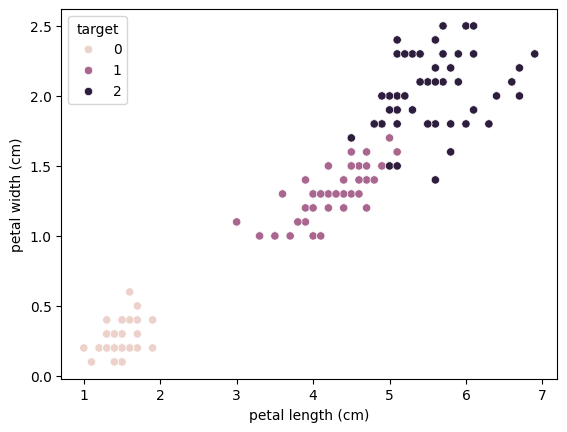

In [ ]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
# Load the Iris dataset
iris = load_iris()
X_clf = iris.data
y_clf = iris.target


print(" Random Forest Classifier Data \n\n")
print("Features shape:", X_clf.shape)
print("Target (y_clf) shape:", y_clf.shape)
print("Target names:", iris.target_names)

# Create a DataFrame for better visualization (optional)
df_clf = pd.DataFrame(X_clf, columns=iris.feature_names)
df_clf['target'] = y_clf
df_clf['target_names'] = df_clf['target'].apply(lambda x: iris.target_names[x])
display(df_clf.head())

print("Features:\n")
sns.scatterplot(data=df_clf, x='petal length (cm)', y='petal width (cm)', hue='target')
plt.show()

In [ ]:
# Split the data into training and testing sets for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

print("X_train_clf shape:", X_train_clf.shape)
print("X_test_clf shape:", X_test_clf.shape)
print("y_train_clf shape:", y_train_clf.shape)
print("y_test_clf shape:", y_test_clf.shape)

X_train_clf shape: (120, 4)
X_test_clf shape: (30, 4)
y_train_clf shape: (120,)
y_test_clf shape: (30,)


Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



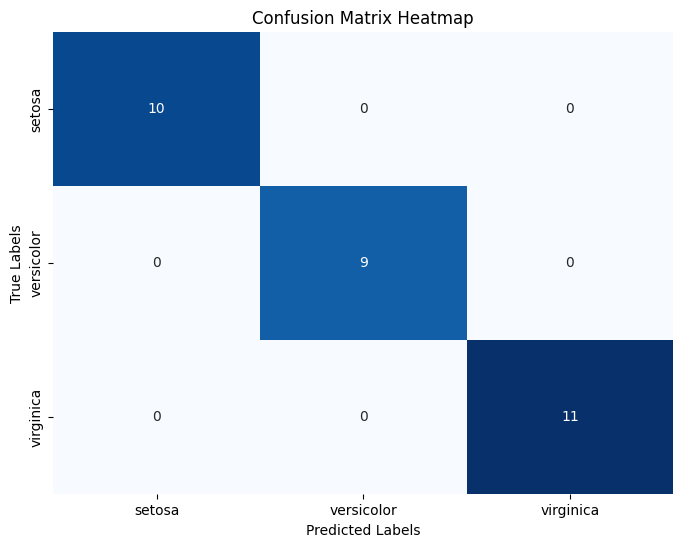

In [ ]:
scaler = StandardScaler()
X_train_clf = scaler.fit_transform(X_train_clf)
X_test_clf = scaler.transform(X_test_clf)

# Initialize the Random Forest Classifier
classifier_model = RandomForestClassifier(n_estimators=80, random_state=42)

# Train the model
classifier_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_clf = classifier_model.predict(X_test_clf)

# Evaluate the classifier model
accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_clf, target_names=iris.target_names))

conf_matrix = confusion_matrix(y_test_clf, y_pred_clf)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

### Support Vector Classifier (SVC) Implementatio

--- Support Vector Classifier Results ---
Accuracy for SVC: 0.9000

Classification Report for SVC:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.78      0.82         9
   virginica       0.83      0.91      0.87        11

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



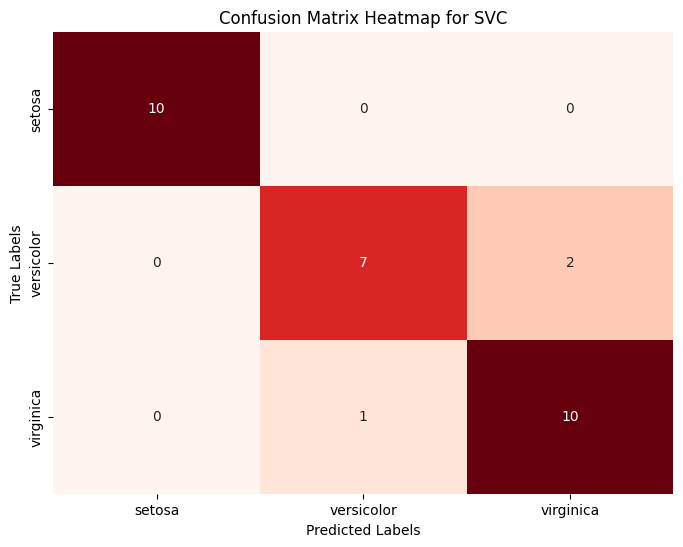

In [ ]:
from sklearn.svm import SVC

# Initialize the Support Vector Classifier
# Set probability=True to enable probability estimates, which are needed for ROC curves.
svc_model = SVC(kernel='sigmoid', C=1.0, random_state=42, probability=True)

# Train the model using the preprocessed Iris classification data
# X_train_clf and y_train_clf are already scaled and defined from the Random Forest section
svc_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_svc = svc_model.predict(X_test_clf)
# Get probability estimates for ROC curve
y_proba_svc = svc_model.predict_proba(X_test_clf)

# Evaluate the SVC model
accuracy_svc = accuracy_score(y_test_clf, y_pred_svc)
print(f" Support Vector Classifier Results ")
print(f"Accuracy for SVC: {accuracy_svc:.4f}")

print("\nClassification Report for SVC:")
print(classification_report(y_test_clf, y_pred_svc, target_names=iris.target_names))

conf_matrix_svc = confusion_matrix(y_test_clf, y_pred_svc)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svc, annot=True, fmt='g', cmap='Reds', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names)

plt.title('Confusion Matrix Heatmap for SVC')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

### Understanding the ROC Curve

An ROC (Receiver Operating Characteristic) curve is a popular tool for understanding the performance of a **classification model**, especially when dealing with imbalanced datasets or when you need to choose an optimal threshold for classification.

Let's understand its components:

*   **X-axis: False Positive Rate (FPR)**
    *   FPR = (False Positives) / (False Positives + True Negatives)
    *   It tells us, "Out of all the actual negative cases, what proportion did the model incorrectly classify as positive?"
    *   A low FPR is good, meaning the model doesn't often cry wolf.

*   **Y-axis: True Positive Rate (TPR) / Recall / Sensitivity**
    *   TPR = (True Positives) / (True Positives + False Negatives)
    *   It tells us, "Out of all the actual positive cases, what proportion did the model correctly identify as positive?"
    *   A high TPR is good, meaning the model catches most of the positive cases.

**What does the curve mean?**

Each point on the ROC curve represents a different classification threshold. As you move along the curve from left to right, you are decreasing the classification threshold, which means the model is becoming more lenient in classifying a sample as positive. This typically increases both the TPR and FPR.

*   An ideal ROC curve hugs the top-left corner, indicating a high TPR and a low FPR across different thresholds. This means the model is very good at distinguishing between positive and negative classes.
*   The red dashed line (often called the "Random Guess" line) represents a classifier that performs no better than random chance. Any good classifier should have its ROC curve above this line.

**Area Under the Curve (AUC)**

The AUC (Area Under the ROC Curve) is a single number that summarizes the overall performance of the classifier across all possible classification thresholds.

*   **AUC ranges from 0 to 1.**
*   **AUC = 1.00** means a perfect classifier that can perfectly separate the positive and negative classes.
*   **AUC = 0.50** means the classifier performs no better than random chance.
*   **AUC < 0.50** means the classifier is worse than random chance (perhaps it's predicting the opposite of what it should).

### Why Your Graph Looks So 'Perfect'

You noticed that many of your curves have an AUC of 1.00 and go straight up and across the top. This happens for a few reasons:

1.  **Highly Separable Dataset**: The Iris dataset is well-known for being relatively easy to classify, especially the 'setosa' class. The features of these flowers make them distinct, so the models can easily tell them apart.
2.  **Excellent Model Performance**: Your Random Forest and Support Vector Classifier models are performing exceptionally well on this dataset. They've learned the patterns so accurately that they can almost perfectly distinguish between the different Iris species on your test data.
3.  **One-vs-Rest (OvR) Strategy for Multi-Class**: For multi-class problems (like the Iris dataset with three types of flowers), we often use an OvR approach. For each class, an ROC curve is plotted where that class is considered 'positive' and all other classes are considered 'negative'. If one class (like 'setosa') is very distinct, the model will have a perfect or near-perfect performance when trying to separate it from the others, leading to an AUC of 1.00 for that specific class's curve.

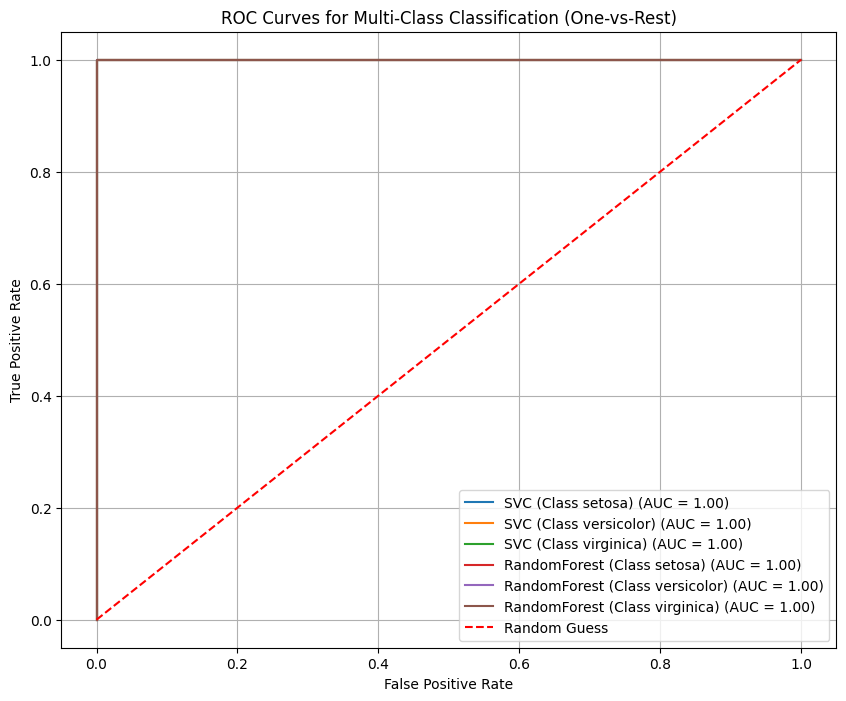

In [ ]:
#ROC curve for multi-class classification (One-vs-Rest)
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelBinarizer

# Get probability predictions from both models
y_proba_svc = svc_model.predict_proba(X_test_clf)
y_proba_rf = classifier_model.predict_proba(X_test_clf)

# One-hot encode the true labels for multi-class ROC
label_binarizer = LabelBinarizer()
y_test_clf_onehot = label_binarizer.fit_transform(y_test_clf)

plt.figure(figsize=(10, 8))

# Plot ROC curves for SVC
for i in range(len(iris.target_names)): # Iterate over each class
    fpr, tpr, _ = roc_curve(y_test_clf_onehot[:, i], y_proba_svc[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'SVC (Class {iris.target_names[i]}) (AUC = {roc_auc:.2f})')

# Plot ROC curves for RandomForest
for i in range(len(iris.target_names)): # Iterate over each class
    fpr, tpr, _ = roc_curve(y_test_clf_onehot[:, i], y_proba_rf[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'RandomForest (Class {iris.target_names[i]}) (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Multi-Class Classification (One-vs-Rest)')
plt.legend()
plt.grid(True)
plt.show()

### ID3 Algorithm Implementation


--- ID3 Algorithm (Decision Tree with Entropy) Results ---
Accuracy for ID3: 1.0000

Classification Report for ID3:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



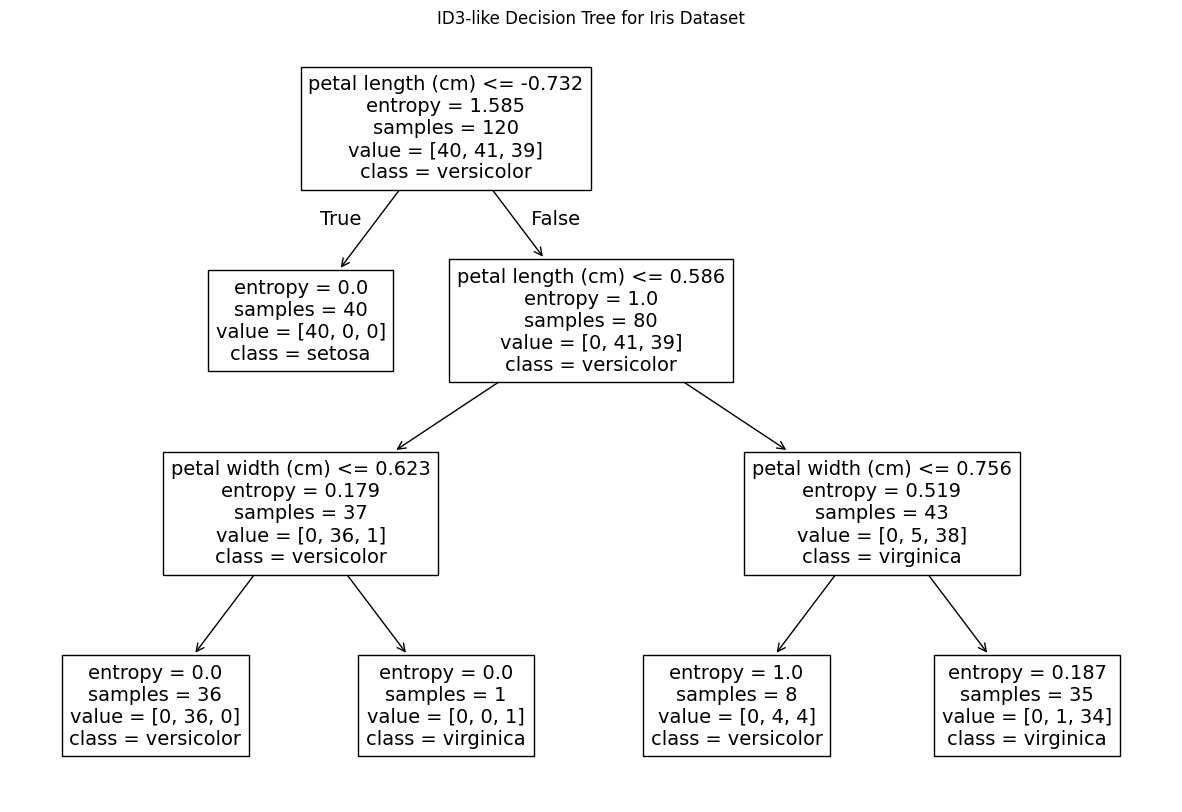

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# Initialize the Decision Tree Classifier with entropy criterion
# max_depth can be set to control the tree's complexity
id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=3)

# Train the model using the preprocessed Iris classification data
id3_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_id3 = id3_model.predict(X_test_clf)

# Evaluate the ID3-like model
accuracy_id3 = accuracy_score(y_test_clf, y_pred_id3)
print(f" ID3 Algorithm (Decision Tree with Entropy) Results ")
print(f"Accuracy for ID3: {accuracy_id3:.4f}")

print("\nClassification Report for ID3:")
print(classification_report(y_test_clf, y_pred_id3, target_names=iris.target_names))

# Optional: Visualize the Decision Tree
plt.figure(figsize=(15, 10))
tree.plot_tree(id3_model, feature_names=iris.feature_names, class_names=iris.target_names, filled=False)
plt.title('ID3-like Decision Tree for Iris Dataset')
plt.show()